# Chapter 4. Implementation
## 4.2 Anisotropic Diffusion Mapping

The pilot search selects the conduction function, time step, and iteration count. These settings are then used to calibrate $K$ and validate the candidate mappings.


## 1. Conduction Function and Fixed Setting Selection

Five calibration images are used for the pilot search. Both conduction functions, three time steps, and the candidate iteration counts are tested. The best overall setting is kept for calibration.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from joblib import Parallel, delayed

# Find the project directory
project_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_dir) not in sys.path:
    sys.path.append(str(project_dir))

from src.denoisers import anisotropic_denoise
from src.noise import add_gaussian_noise
from src.utils import load_grayscale_image
from src.metrics import calculate_psnr, calculate_ssim


In [2]:
# Experiment settings
noise_levels = [2, 4, 6, 8, 10, 12, 15]
seed = 42
num_calibration = 50
num_validation = 30
num_pilot = 5

# Candidate conduction functions and fixed settings
conduction_values = ["exponential", "reciprocal"]
time_step_values = [0.10, 0.15, 0.20]
iteration_values = list(range(1, 21))
# iteration_values = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 15, 20]

# Coarse K candidates for images normalised to [0, 1]
coarse_k_values = [
    0.01, 0.02, 0.04, 0.06, 0.08, 0.10, 0.12, 0.15, 0.18,
    0.22, 0.26, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60
]

calibration_dir = project_dir / "data" / "calibration"
result_dir = project_dir / "results" / "Chapter4_AD_Calibration"
result_dir.mkdir(parents=True, exist_ok=True)

print("Calibration directory:", calibration_dir)
print("Noise levels (%):", noise_levels)
print("Conduction candidates:", conduction_values)
print("Time-step candidates:", time_step_values)
print("Iteration candidates:", iteration_values)
print("Seed:", seed)


Calibration directory: D:\MScProject\data\calibration
Noise levels (%): [2, 4, 6, 8, 10, 12, 15]
Conduction candidates: ['exponential', 'reciprocal']
Time-step candidates: [0.1, 0.15, 0.2]
Iteration candidates: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
Seed: 42


In [3]:
# Find all image files
image_files = []

for pattern in ["*.png", "*.jpg", "*.jpeg", "*.bmp", "*.tif", "*.tiff"]:
    image_files.extend(calibration_dir.glob(pattern))

image_files = sorted(image_files)
required_images = num_calibration + num_validation

if len(image_files) < required_images:
    raise FileNotFoundError(
        f"At least {required_images} images are required, but only {len(image_files)} were found in {calibration_dir}"
    )

# Create reproducible calibration and validation sets
split_rng = np.random.default_rng(seed)
shuffled_indices = split_rng.permutation(len(image_files))
calibration_indices = shuffled_indices[:num_calibration]
validation_indices = shuffled_indices[num_calibration:required_images]

calibration_files = sorted([image_files[index] for index in calibration_indices])
validation_files = sorted([image_files[index] for index in validation_indices])

# Select five pilot images from the calibration set
pilot_rng = np.random.default_rng(seed)
pilot_indices = pilot_rng.choice(len(calibration_files), size=num_pilot, replace=False)
pilot_files = [calibration_files[index] for index in pilot_indices]
pilot_names = [image_file.stem for image_file in pilot_files]

# Load the selected clean images
calibration_images = {
    image_file.stem: load_grayscale_image(image_file) for image_file in calibration_files
}
validation_images = {
    image_file.stem: load_grayscale_image(image_file) for image_file in validation_files
}

print("Number of calibration images:", len(calibration_images))
print("Calibration image IDs:")
print(", ".join(image_file.stem for image_file in calibration_files))

print("\nNumber of validation images:", len(validation_images))
print("Validation image IDs:")
print(", ".join(image_file.stem for image_file in validation_files))

print("\nNumber of pilot images:", len(pilot_files))
print("Pilot image IDs:")
print(", ".join(sorted(pilot_names)))


Number of calibration images: 50
Calibration image IDs:
004, 008, 009, 010, 021, 025, 026, 027, 030, 034, 038, 039, 047, 051, 052, 055, 057, 068, 071, 076, 080, 085, 093, 097, 102, 105, 107, 116, 122, 131, 134, 139, 145, 148, 149, 151, 153, 154, 158, 165, 172, 174, 177, 179, 188, 189, 190, 191, 197, 198

Number of validation images: 30
Validation image IDs:
001, 003, 005, 013, 028, 029, 033, 053, 056, 063, 067, 069, 081, 082, 083, 087, 089, 090, 095, 099, 104, 109, 113, 115, 119, 135, 144, 156, 181, 200

Number of pilot images: 5
Pilot image IDs:
021, 085, 139, 153, 198


In [5]:
# Search conduction functions, fixed settings, and coarse K values
def evaluate_pilot_candidates(image_name, noise_percent):
    clean_image = calibration_images[image_name]

    # Generate one noisy image for this image-noise case
    noisy_image = add_gaussian_noise(clean_image, sigma=noise_percent / 100, seed=seed).astype(np.float32)
    image_results = []

    for conduction_value in conduction_values:
        for time_step_value in time_step_values:
            for n_iter in iteration_values:
                for k_value in coarse_k_values:
                    denoised_image, _ = anisotropic_denoise(
                        noisy_image, n_iter=n_iter, kappa=k_value,
                        gamma=time_step_value, conduction=conduction_value
                    )
                    psnr = calculate_psnr(clean_image, denoised_image)

                    image_results.append({
                        "image": image_name,
                        "noise_sigma": noise_percent,
                        "conduction": conduction_value,
                        "time_step": time_step_value,
                        "n_iter": n_iter,
                        "kappa": k_value,
                        "psnr": psnr
                    })

    return image_results


pilot_outputs = Parallel(n_jobs=16, prefer="threads", verbose=5)(
    delayed(evaluate_pilot_candidates)(image_name, noise_percent)
    for noise_percent in noise_levels
    for image_name in pilot_names
)

pilot_results = pd.DataFrame([row for output in pilot_outputs for row in output])
print("Pilot results:", len(pilot_results))


[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  12 out of  35 | elapsed:  5.9min remaining: 11.2min
[Parallel(n_jobs=16)]: Done  20 out of  35 | elapsed: 11.2min remaining:  8.4min
[Parallel(n_jobs=16)]: Done  28 out of  35 | elapsed: 11.2min remaining:  2.8min


Pilot results: 75600


[Parallel(n_jobs=16)]: Done  35 out of  35 | elapsed: 11.9min finished


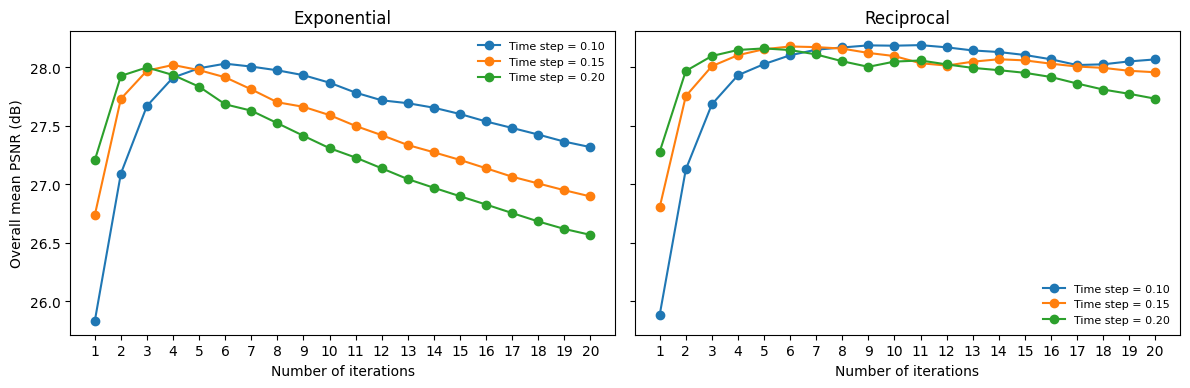

Selected conduction function: reciprocal
Selected fixed time step: 0.1
Selected fixed iteration count: 11


,conduction,time_step,n_iter,overall_mean_psnr
0,reciprocal,0.1,11,28.190449
1,exponential,0.1,6,28.031922


,noise_sigma,conduction,time_step,n_iter,kappa,psnr
0,2,reciprocal,0.1,11,0.02,35.259994
1,4,reciprocal,0.1,11,0.04,30.916253
2,6,reciprocal,0.1,11,0.06,28.600866
3,8,reciprocal,0.1,11,0.10,27.150241
4,10,reciprocal,0.1,11,0.12,26.065911
5,12,reciprocal,0.1,11,0.15,25.189892
6,15,reciprocal,0.1,11,0.22,24.149985


,noise_sigma,fine_k_values
0,2,"0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08..."
1,4,"0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08..."
2,6,"0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08..."
3,8,"0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08..."
4,10,"0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09..."
5,12,"0.05, 0.06, 0.07, 0.08, 0.09, 0.1, 0.11, 0.12,..."
6,15,"0.12, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19..."


In [6]:
# Average the pilot results across images
pilot_mean = pilot_results.groupby(
    ["noise_sigma", "conduction", "time_step", "n_iter", "kappa"], as_index=False
)["psnr"].mean()

# Find the best K for each fixed-setting combination and noise level
pilot_best_indices = pilot_mean.groupby(
    ["noise_sigma", "conduction", "time_step", "n_iter"]
)["psnr"].idxmax()

pilot_best_by_setting = (
    pilot_mean.loc[pilot_best_indices]
    .sort_values(["conduction", "time_step", "n_iter", "noise_sigma"])
    .reset_index(drop=True)
)

# Compare the best fixed combination for each conduction function
fixed_setting_summary = (
    pilot_best_by_setting.groupby(["conduction", "time_step", "n_iter"], as_index=False)["psnr"]
    .mean()
    .rename(columns={"psnr": "overall_mean_psnr"})
)

best_function_indices = fixed_setting_summary.groupby("conduction")["overall_mean_psnr"].idxmax()
best_setting_by_conduction = (
    fixed_setting_summary.loc[best_function_indices]
    .sort_values("overall_mean_psnr", ascending=False)
    .reset_index(drop=True)
)

# Select the best conduction, time-step, and iteration combination
best_setting_index = fixed_setting_summary["overall_mean_psnr"].idxmax()
conduction = str(fixed_setting_summary.loc[best_setting_index, "conduction"])
time_step = float(fixed_setting_summary.loc[best_setting_index, "time_step"])
n_iterations = int(fixed_setting_summary.loc[best_setting_index, "n_iter"])

selected_pilot_best = (
    pilot_best_by_setting[
        (pilot_best_by_setting["conduction"] == conduction)
        & (pilot_best_by_setting["time_step"] == time_step)
        & (pilot_best_by_setting["n_iter"] == n_iterations)
    ]
    .sort_values("noise_sigma")
    .reset_index(drop=True)
)

# Build a wider fine K range around each selected coarse optimum
fine_k_values = {}

for _, row in selected_pilot_best.iterrows():
    noise_percent = int(row["noise_sigma"])
    centre = float(row["kappa"])
    candidates = np.arange(centre - 0.10, centre + 0.1001, 0.01)
    fine_k_values[noise_percent] = np.round(
        [value for value in candidates if value >= 0.005], 3
    ).tolist()

    if centre == min(coarse_k_values) or centre == max(coarse_k_values):
        print(f"Warning: {noise_percent}% reached a coarse K-search boundary.")

if n_iterations in {min(iteration_values), max(iteration_values)}:
    print("Warning: the selected iteration count is at the search boundary.")

fine_k_table = pd.DataFrame({
    "noise_sigma": list(fine_k_values),
    "fine_k_values": [", ".join(map(str, values)) for values in fine_k_values.values()]
})

# Compare time-step and iteration combinations for both functions
fig, axes = plt.subplots(1, len(conduction_values), figsize=(12, 4.2), sharex=True, sharey=True)
axes = np.atleast_1d(axes)

for ax, conduction_value in zip(axes, conduction_values):
    for time_step_value in time_step_values:
        current = fixed_setting_summary[
            (fixed_setting_summary["conduction"] == conduction_value)
            & (fixed_setting_summary["time_step"] == time_step_value)
        ].sort_values("n_iter")

        ax.plot(
            current["n_iter"], current["overall_mean_psnr"], marker="o",
            label=f"Time step = {time_step_value:.2f}"
        )

    ax.set_title(conduction_value.capitalize())
    ax.set_xlabel("Number of iterations")
    ax.set_xticks(iteration_values)
    ax.legend(frameon=False, fontsize=8)

axes[0].set_ylabel("Overall mean PSNR (dB)")
# fig.suptitle("Fixed setting selection")
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig(result_dir / "ad_fixed_setting_search.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Selected conduction function: {conduction}")
print(f"Selected fixed time step: {time_step}")
print(f"Selected fixed iteration count: {n_iterations}")
display(best_setting_by_conduction)
display(selected_pilot_best)
display(fine_k_table)


## 2. Calibration

Using the selected fixed settings, $K$ is fine-tuned at each noise level on all fifty calibration images. The selected values are used to build three mappings.


In [7]:
# Run the fine K search on all calibration images
def evaluate_calibration_image(image_name, clean_image, noise_percent):
    # Generate one noisy image for this image-noise case
    noisy_image = add_gaussian_noise(clean_image, sigma=noise_percent / 100, seed=seed).astype(np.float32)
    image_results = []

    for k_value in fine_k_values[noise_percent]:
        denoised_image, _ = anisotropic_denoise(
            noisy_image, n_iter=n_iterations, kappa=k_value,
            gamma=time_step, conduction=conduction
        )
        psnr = calculate_psnr(clean_image, denoised_image)

        image_results.append({
            "image": image_name,
            "noise_sigma": noise_percent,
            "seed": seed,
            "n_iter": n_iterations,
            "time_step": time_step,
            "kappa": k_value,
            "psnr": psnr
        })

    return image_results


fine_outputs = Parallel(n_jobs=16, prefer="threads", verbose=5)(
    delayed(evaluate_calibration_image)(image_name, clean_image, noise_percent)
    for noise_percent in noise_levels
    for image_name, clean_image in calibration_images.items()
)

grid_results = pd.DataFrame([row for output in fine_outputs for row in output])
print("Fine-search results:", len(grid_results))


[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  40 tasks      | elapsed:    5.7s
[Parallel(n_jobs=16)]: Done 130 tasks      | elapsed:   18.6s
[Parallel(n_jobs=16)]: Done 256 tasks      | elapsed:   41.0s


Fine-search results: 6250


[Parallel(n_jobs=16)]: Done 350 out of 350 | elapsed:   58.8s finished


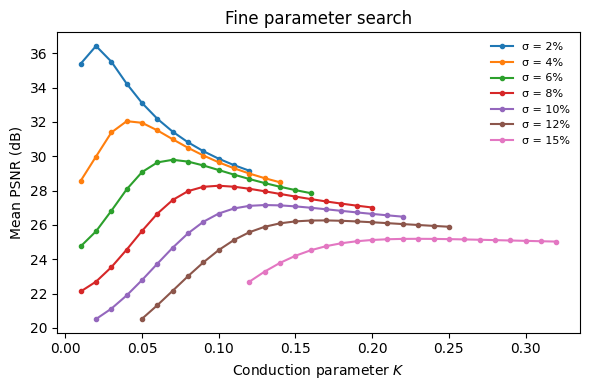

,noise_sigma,kappa,psnr
0,2,0.02,36.417745
1,4,0.04,32.039676
2,6,0.07,29.790584
3,8,0.10,28.279977
4,10,0.13,27.156326
5,12,0.17,26.260628
6,15,0.23,25.189789


In [8]:
# Average PSNR across the fifty calibration images
mean_results = grid_results.groupby(["noise_sigma", "kappa"], as_index=False)["psnr"].mean()

# Select K with the highest mean PSNR at each noise level
best_indices = mean_results.groupby("noise_sigma")["psnr"].idxmax()
best_parameters = mean_results.loc[best_indices].sort_values("noise_sigma").reset_index(drop=True)

# Check whether any selected K is at a fine-search boundary
for _, row in best_parameters.iterrows():
    noise_percent = int(row["noise_sigma"])
    selected_k = float(row["kappa"])
    current_range = fine_k_values[noise_percent]

    if selected_k in {min(current_range), max(current_range)}:
        print(f"Warning: {noise_percent}% reached a fine K-search boundary.")

# Plot the fine-search curves
fig, ax = plt.subplots(figsize=(6, 4))

for noise_percent in noise_levels:
    current = mean_results[mean_results["noise_sigma"] == noise_percent]
    ax.plot(
        current["kappa"], current["psnr"], marker="o", markersize=3,
        label=f"σ = {noise_percent}%"
    )

ax.set_xlabel(r"Conduction parameter $K$")
ax.set_ylabel("Mean PSNR (dB)")
ax.set_title("Fine parameter search")
ax.legend(frameon=False, fontsize=8)

fig.tight_layout()
fig.savefig(result_dir / "ad_fine_search.png", dpi=300, bbox_inches="tight")
plt.show()

best_parameters


Fixed iterations: 11
Fixed time step: 0.1
Mapping: K = 0.000424σ² + 0.009033σ - 0.000671
R² = 0.9996


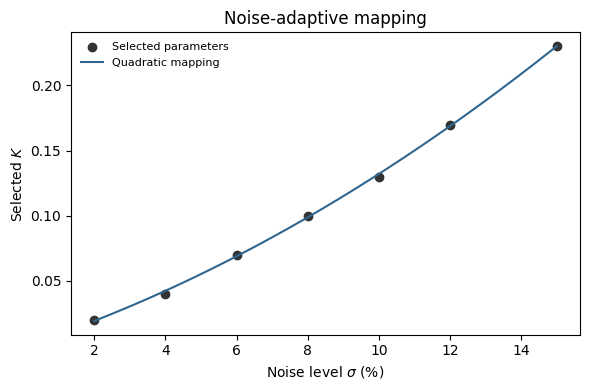

,noise_sigma,kappa,psnr
0,2,0.02,36.417745
1,4,0.04,32.039676
2,6,0.07,29.790584
3,8,0.10,28.279977
4,10,0.13,27.156326
5,12,0.17,26.260628
6,15,0.23,25.189789


,n_iterations,time_step,conduction,quadratic_a,quadratic_b,quadratic_c,r_squared,minimum_k,maximum_k
0,11,0.1,reciprocal,0.000424,0.009033,-0.000671,0.999555,0.02,0.23


In [9]:
# Fit a quadratic noise-to-parameter mapping
noise_values = best_parameters["noise_sigma"].to_numpy(dtype=float)
k_values = best_parameters["kappa"].to_numpy(dtype=float)

quadratic_coefficients = np.polyfit(noise_values, k_values, 2)
quadratic_values = np.polyval(quadratic_coefficients, noise_values)

residual_sum = np.sum((k_values - quadratic_values) ** 2)
total_sum = np.sum((k_values - np.mean(k_values)) ** 2)
r_squared = 1 - residual_sum / total_sum if total_sum > 0 else 0.0

# Keep every mapping inside the parameter range selected during calibration
minimum_k = float(k_values.min())
maximum_k = float(k_values.max())
quadratic_a, quadratic_b, quadratic_c = quadratic_coefficients

mapping = pd.DataFrame({
    "n_iterations": [n_iterations],
    "time_step": [time_step],
    "conduction": [conduction],
    "quadratic_a": [quadratic_a],
    "quadratic_b": [quadratic_b],
    "quadratic_c": [quadratic_c],
    "r_squared": [r_squared],
    "minimum_k": [minimum_k],
    "maximum_k": [maximum_k]
})

print(f"Fixed iterations: {n_iterations}")
print(f"Fixed time step: {time_step}")

b_sign = "+" if quadratic_b >= 0 else "-"
c_sign = "+" if quadratic_c >= 0 else "-"
print(
    f"Mapping: K = {quadratic_a:.6f}σ² {b_sign} {abs(quadratic_b):.6f}σ "
    f"{c_sign} {abs(quadratic_c):.6f}"
)
print(f"R² = {r_squared:.4f}")

# Plot the selected parameters and quadratic mapping
fig, ax = plt.subplots(figsize=(6, 4))
plot_noise = np.linspace(min(noise_values), max(noise_values), 200)

ax.scatter(noise_values, k_values, color="#333333", label="Selected parameters")
ax.plot(
    plot_noise, np.polyval(quadratic_coefficients, plot_noise),
    color="#2F6690", label="Quadratic mapping"
)

ax.set_xlabel(r"Noise level $\sigma$ (%)")
ax.set_ylabel(r"Selected $K$")
ax.set_title("Noise-adaptive mapping")
ax.legend(frameon=False, fontsize=8)

fig.tight_layout()
fig.savefig(result_dir / "ad_parameter_mapping.png", dpi=300, bbox_inches="tight")
plt.show()

display(best_parameters)
display(mapping)


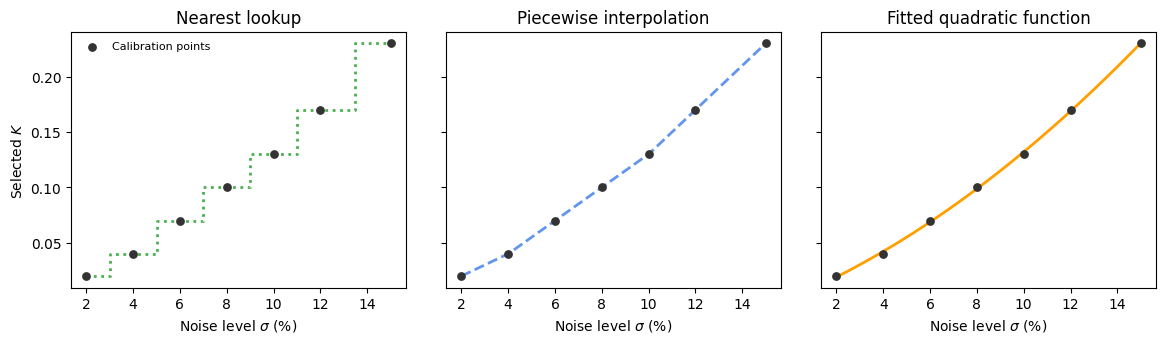

,noise_sigma,lookup_k,interpolated_k,quadratic_k
0,2,0.02,0.020,0.020000
1,3,0.02,0.030,0.030245
2,4,0.04,0.040,0.042247
3,5,0.04,0.055,0.055097
4,6,0.07,0.070,0.068796
5,7,0.07,0.085,0.083343
6,8,0.10,0.100,0.098738
7,9,0.10,0.115,0.114981
8,10,0.13,0.130,0.132073
9,11,0.13,0.150,0.150012


In [10]:
# Define the three candidate mapping strategies
def select_k_lookup(estimated_sigma_percent):
    distances = np.abs(noise_values - estimated_sigma_percent)
    nearest_index = int(np.argmin(distances))
    return float(k_values[nearest_index])


def select_k_interpolated(estimated_sigma_percent):
    return float(np.interp(estimated_sigma_percent, noise_values, k_values))


def select_k_quadratic(estimated_sigma_percent):
    k_value = np.polyval(quadratic_coefficients, estimated_sigma_percent)
    return float(np.clip(k_value, minimum_k, maximum_k))


# Add noise levels between the calibration points
intermediate_noise_levels = [3, 5, 7, 9, 11, 13, 14]
validation_noise_levels = sorted(set(noise_levels + intermediate_noise_levels))

# Display the parameters returned by all three strategies
mapping_comparison = pd.DataFrame({
    "noise_sigma": validation_noise_levels,
    "lookup_k": [select_k_lookup(value) for value in validation_noise_levels],
    "interpolated_k": [select_k_interpolated(value) for value in validation_noise_levels],
    "quadratic_k": [select_k_quadratic(value) for value in validation_noise_levels]
})

# Plot lookup, interpolation, and the quadratic function
plot_noise = np.linspace(min(noise_values), max(noise_values), 400)
lookup_plot = [select_k_lookup(value) for value in plot_noise]
interpolated_plot = [select_k_interpolated(value) for value in plot_noise]
quadratic_plot = [select_k_quadratic(value) for value in plot_noise]

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True, sharey=True)

axes[0].scatter(noise_values, k_values, color="#333333", s=28, label="Calibration points", zorder=4)
axes[0].step(plot_noise, lookup_plot, where="mid", color="#4CAF50", linewidth=2, linestyle=":")
axes[0].set_title("Nearest lookup")

axes[1].scatter(noise_values, k_values, color="#333333", s=28, zorder=4)
axes[1].plot(plot_noise, interpolated_plot, color="#6495ED", linewidth=2, linestyle="--")
axes[1].set_title("Piecewise interpolation")

axes[2].scatter(noise_values, k_values, color="#333333", s=28, zorder=4)
axes[2].plot(plot_noise, quadratic_plot, color="#FFA000", linewidth=2)
axes[2].set_title("Fitted quadratic function")

for ax in axes:
    ax.set_xlabel(r"Noise level $\sigma$ (%)")

axes[0].set_ylabel(r"Selected $K$")
axes[0].legend(frameon=False, fontsize=8)

fig.subplots_adjust(top=0.82, bottom=0.18, wspace=0.12)
fig.savefig(result_dir / "ad_mapping_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

mapping_comparison


## 3. Validation

The three mappings are evaluated on thirty validation images. Final selection uses the intermediate noise levels, which were not used in calibration.


In [11]:
# Evaluate the three mapping strategies on the validation images
def validate_image(image_name, clean_image, noise_percent):
    # Generate one noisy image and reuse it for all three strategies
    noisy_image = add_gaussian_noise(clean_image, sigma=noise_percent / 100, seed=seed).astype(np.float32)

    lookup_k = select_k_lookup(noise_percent)
    interpolated_k = select_k_interpolated(noise_percent)
    quadratic_k = select_k_quadratic(noise_percent)

    lookup_image, _ = anisotropic_denoise(
        noisy_image, n_iter=n_iterations, kappa=lookup_k, gamma=time_step, conduction=conduction
    )
    interpolated_image, _ = anisotropic_denoise(
        noisy_image, n_iter=n_iterations, kappa=interpolated_k, gamma=time_step, conduction=conduction
    )
    quadratic_image, _ = anisotropic_denoise(
        noisy_image, n_iter=n_iterations, kappa=quadratic_k, gamma=time_step, conduction=conduction
    )

    return {
        "image": image_name,
        "noise_sigma": noise_percent,
        "n_iter": n_iterations,
        "time_step": time_step,
        "lookup_k": lookup_k,
        "interpolated_k": interpolated_k,
        "quadratic_k": quadratic_k,
        "noisy_psnr": calculate_psnr(clean_image, noisy_image),
        "lookup_psnr": calculate_psnr(clean_image, lookup_image),
        "interpolated_psnr": calculate_psnr(clean_image, interpolated_image),
        "quadratic_psnr": calculate_psnr(clean_image, quadratic_image),
        "noisy_ssim": calculate_ssim(clean_image, noisy_image),
        "lookup_ssim": calculate_ssim(clean_image, lookup_image),
        "interpolated_ssim": calculate_ssim(clean_image, interpolated_image),
        "quadratic_ssim": calculate_ssim(clean_image, quadratic_image)
    }


validation_rows = Parallel(n_jobs=16, prefer="threads", verbose=5)(
    delayed(validate_image)(image_name, clean_image, noise_percent)
    for noise_percent in validation_noise_levels
    for image_name, clean_image in validation_images.items()
)

validation_results = pd.DataFrame(validation_rows)
validation_summary = validation_results.groupby("noise_sigma", as_index=False)[
    [
        "lookup_k", "interpolated_k", "quadratic_k", "noisy_psnr",
        "lookup_psnr", "interpolated_psnr", "quadratic_psnr"
    ]
].mean()

# Select the final strategy using only the intermediate noise levels
intermediate_results = validation_results[
    validation_results["noise_sigma"].isin(intermediate_noise_levels)
]
mean_noisy_psnr = intermediate_results["noisy_psnr"].mean()

method_rows = []

for method_name, psnr_column in {
    "Nearest lookup": "lookup_psnr",
    "Piecewise interpolation": "interpolated_psnr",
    "Fitted quadratic function": "quadratic_psnr"
}.items():
    mean_psnr = intermediate_results[psnr_column].mean()
    method_rows.append({
        "mapping_method": method_name,
        "mean_psnr": mean_psnr,
        "gain_over_noisy": mean_psnr - mean_noisy_psnr
    })

validation_method_summary = (
    pd.DataFrame(method_rows)
    .sort_values("mean_psnr", ascending=False)
    .reset_index(drop=True)
)

selected_mapping_method = validation_method_summary.loc[0, "mapping_method"]

print("Selected mapping method:", selected_mapping_method)
display(validation_summary)
display(validation_method_summary)


[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  40 tasks      | elapsed:    3.3s
[Parallel(n_jobs=16)]: Done 130 tasks      | elapsed:    8.3s
[Parallel(n_jobs=16)]: Done 256 tasks      | elapsed:   14.6s


Selected mapping method: Fitted quadratic function


[Parallel(n_jobs=16)]: Done 420 out of 420 | elapsed:   22.8s finished


,noise_sigma,lookup_k,interpolated_k,quadratic_k,noisy_psnr,lookup_psnr,interpolated_psnr,quadratic_psnr
0,2,0.02,0.020,0.020000,33.945304,36.721667,36.721667,36.721667
1,3,0.02,0.030,0.030245,30.423479,33.246103,34.119312,34.122878
2,4,0.04,0.040,0.042247,27.924704,32.349574,32.349574,32.393145
3,5,0.04,0.055,0.055097,25.986504,30.350676,31.115579,31.116432
4,6,0.07,0.070,0.068796,24.402879,30.118548,30.118548,30.113163
5,7,0.07,0.085,0.083343,23.063943,29.018836,29.293540,29.289333
6,8,0.10,0.100,0.098738,21.904104,28.592131,28.592131,28.590102
7,9,0.10,0.115,0.114981,20.881053,27.832029,27.981303,27.981281
8,10,0.13,0.130,0.132073,19.965904,27.438707,27.438707,27.440651
9,11,0.13,0.150,0.150012,19.138050,26.836724,26.953694,26.953690


,mapping_method,mean_psnr,gain_over_noisy
0,Fitted quadratic function,28.756823,6.724907
1,Piecewise interpolation,28.756477,6.724562
2,Nearest lookup,28.434383,6.402468


In [12]:
# Show validation results at intermediate noise levels
validation_table = (
    validation_summary[validation_summary["noise_sigma"].isin(intermediate_noise_levels)][
        ["noise_sigma", "lookup_psnr", "interpolated_psnr", "quadratic_psnr"]
    ]
    .rename(columns={
        "noise_sigma": "Noise level (%)",
        "lookup_psnr": "Nearest lookup",
        "interpolated_psnr": "Piecewise interpolation",
        "quadratic_psnr": "Fitted quadratic function"
    })
    .round(3)
)

mean_row = pd.DataFrame({
    "Noise level (%)": ["Mean"],
    "Nearest lookup": [validation_table["Nearest lookup"].mean()],
    "Piecewise interpolation": [validation_table["Piecewise interpolation"].mean()],
    "Fitted quadratic function": [validation_table["Fitted quadratic function"].mean()]
}).round(3)

validation_table = pd.concat([validation_table, mean_row], ignore_index=True)
validation_table


,Noise level (%),Nearest lookup,Piecewise interpolation,Fitted quadratic function
0,3,33.246,34.119,34.123
1,5,30.351,31.116,31.116
2,7,29.019,29.294,29.289
3,9,27.832,27.981,27.981
4,11,26.837,26.954,26.954
5,13,26.068,26.103,26.104
6,14,25.689,25.729,25.730
7,Mean,28.435,28.757,28.757
